# Precision at 5

**이 노트북에서 할 일**

1. 앞 다섯 자리에 정답 문서가 든 비율을 정밀도로 계산합니다.
2. 받은 개수가 모자라도 나누는 수를 5로 고정하는 까닭을 확인합니다.
3. 자르는 자리를 바꿔 정밀도와 재현율이 어느 쪽으로 움직이는지 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 열여섯 번입니다. 색인 한 벌에 한 번, 질문 검색에 열다섯 번입니다.

02절보다 한 번 적습니다. 첫 질문을 따로 검색하지 않고 반복 검색 결과에서 꺼내 쓰기 때문입니다.
답을 쓰는 모델은 이 절에서 부르지 않습니다.

보낼 조각 수는 색인이 59190개 어림이고 질문은 한 번에 스무 개 안팎입니다.
예상 비용은 열여섯 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)의 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

**데이터** — 읽는 파일은 네 갈래이고 모두 실습 묶음에 들어 있습니다.

- 말뭉치 `labs/data/rag-corpus/pdf/`의 디지털 PDF 18건과 `labs/data/rag-corpus/manifest.json`
- 평가셋 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`
- Ch 9 06절 기록 `labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl`
- Ch 10 08절 기록 `labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl`

이 절은 파일을 쓰지 않습니다. 02절과 같은 기준선을 같은 코드로 다시 만듭니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 설명합니다.
정답 문서 수로 최댓값 재기, 정밀도 함수 만들기, 고정 분모 확인, 앞 챕터 기록으로 잴 수 있는 자리입니다.
6~11절은 함께 실행하고 실습 시간에 다시 읽습니다.
5절 색인 만들기는 02절과 같은 코드라 실행만 하고 빠르게 넘어갑니다.

**기준 버전** — 고정한 패키지는 다섯 개입니다.

- 쪽 읽기: pypdf 6.1.1
- 색인과 임베딩: langchain-core 1.6.2 · langchain-openai 1.6.0
- 코사인 유사도 계산: numpy 2.5.3
- 키 읽기: python-dotenv 1.2.3

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch11-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

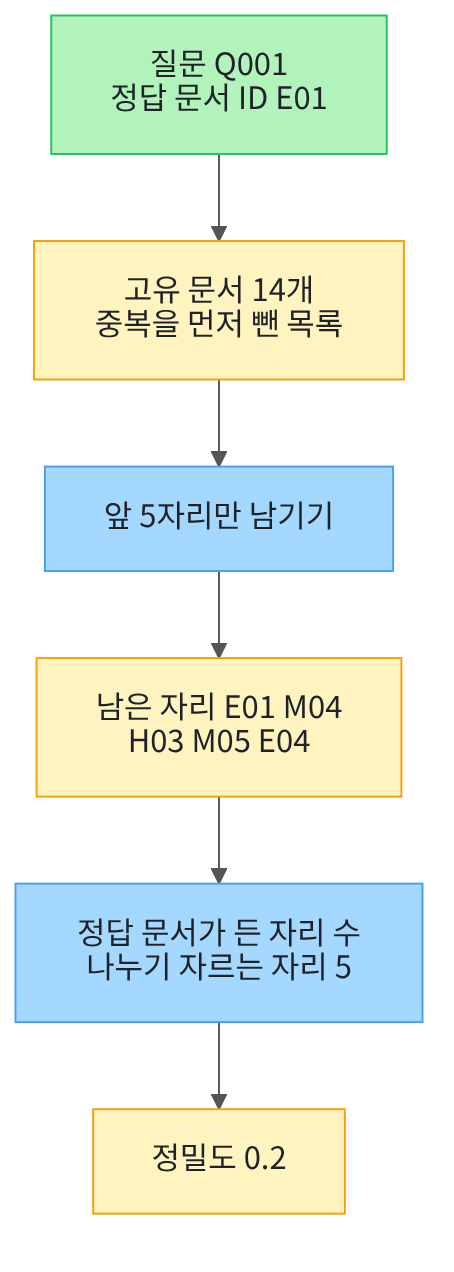

맨 위 초록 상자가 이 절의 입력입니다. 질문 하나와 그 질문의 정답 문서 ID입니다.
그 아래 노란 상자가 02절에서 만든 고유 문서 목록이고, 파란 상자에서 앞 5자리만 남깁니다.
맨 아래 두 상자가 이 절의 계산입니다. 정답 문서가 든 자리 수를 자르는 자리 5로 나눕니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
02절에서 쓴 다섯 개와 같습니다. 이 절도 검색을 직접 하기 때문입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.1.1" "langchain-core==1.6.2" "langchain-openai==1.6.0" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.1.1
langchain-core: 1.6.2
langchain-openai: 1.6.0
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 다섯 줄 가운데 첫 줄은 `pypdf: 6.1.1`입니다.
둘째 줄 `langchain-core: 1.6.2`와 셋째 줄 `langchain-openai: 1.6.0`도 보세요.
넷째 줄 `numpy: 2.5.3`은 색인이 코사인 유사도를 계산할 때 쓰는 패키지입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다. 02절과 같은 여섯 줄입니다.

In [2]:
# 평가셋과 실행 기록 읽기·PDF 읽기·문서 객체·임베딩·색인에 쓸 이름을 불러옵니다
import json

from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from pypdf import PdfReader

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
이 셀은 모듈 `os`도 함께 불러옵니다. 다음 셀에서 파일이 있는지 확인할 때 씁니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01·02절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 고른 경로에 파일 이름을 이어 붙여 네 갈래 경로를 만듭니다.

In [5]:
# 이 절에서 읽을 파일 네 갈래의 경로를 만듭니다
corpus_path = root_path + "/labs/data/rag-corpus"
manifest_path = corpus_path + "/manifest.json"
dataset_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
ch09_log_path = root_path + "/labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl"
ch10_log_path = root_path + "/labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl"
print("평가셋 파일이 있는가:", os.path.exists(dataset_path))
print("말뭉치 목록이 있는가:", os.path.exists(manifest_path))
print("Ch 9 기록이 있는가:", os.path.exists(ch09_log_path))
print("Ch 10 기록이 있는가:", os.path.exists(ch10_log_path))

평가셋 파일이 있는가: True
말뭉치 목록이 있는가: True
Ch 9 기록이 있는가: True
Ch 10 기록이 있는가: True


**결과 읽기** — 네 줄 모두 `True`입니다. 02절이 읽은 네 갈래와 같습니다.

## 2. 정답 문서 수로 최댓값 재기

평가셋 30줄을 읽고 개발 분할 15문항만 남깁니다. 02절과 같은 코드입니다.
시험 분할은 설정을 다 고른 뒤 한 번만 보기로 01절에서 정했습니다.

In [6]:
# 평가셋 30줄을 읽고 설정을 고를 때 쓰는 개발 분할만 남깁니다
with open(dataset_path, encoding="utf-8") as dataset_file:
    dataset_lines = dataset_file.read().splitlines()

queries = []
for line in dataset_lines:
    queries.append(json.loads(line))

dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
print("평가셋 줄 수:", len(queries))
print("개발 분할 질문 수:", len(dev_queries))
print("첫 질문 번호:", dev_queries[0]["qid"])

평가셋 줄 수: 30
개발 분할 질문 수: 15
첫 질문 번호: Q001


**결과 읽기** — 출력 줄은 `평가셋 줄 수: 30`과 `개발 분할 질문 수: 15`입니다.
셋째 줄 `첫 질문 번호: Q001`은 02절에서 후보 목록을 처음 본 그 질문입니다.

다음 셀은 질문마다 정답 문서 ID가 몇 개인지 셉니다.
정답 문서가 한 개면 앞 5자리에서 셀 수 있는 정답 자리도 많아야 한 개입니다.
그래서 이 평가셋에서 자리 5의 값이 얼마까지 올라갈 수 있는지 미리 알 수 있습니다.

In [7]:
# 정답 문서 ID가 한 개인 질문을 세어 자르는 자리 5에서 나올 수 있는 최댓값을 봅니다
cutoff_narrow = 5
single_gold_count = 0
for query in dev_queries:
    if len(query["gold_doc_ids"]) == 1:
        single_gold_count = single_gold_count + 1

max_precision = 1 / cutoff_narrow
print("개발 분할 질문 수:", len(dev_queries))
print("정답 문서 ID가 한 개인 질문 수:", single_gold_count)
print("정답 문서가 한 개일 때 자리 5의 최댓값:", max_precision)

개발 분할 질문 수: 15
정답 문서 ID가 한 개인 질문 수: 15
정답 문서가 한 개일 때 자리 5의 최댓값: 0.2


**결과 읽기** — 둘째 줄은 `정답 문서 ID가 한 개인 질문 수: 15`입니다.
개발 분할 15문항이 모두 정답 문서 한 개짜리입니다.
셋째 줄 `정답 문서가 한 개일 때 자리 5의 최댓값: 0.2`가 이 절 값을 읽는 기준입니다.
01절 7절에서 30문항 전체가 정답 문서 한 개라는 것을 이미 보았습니다.

## 3. 정밀도 함수 만들기

01절 12절에서 만든 함수를 같은 코드로 가져옵니다.
검색 항목에서 처음 나온 문서 ID만 순서대로 남기는 함수입니다.

In [8]:
# 검색 항목에서 문서 ID를 순서대로 모으고 처음 나온 것만 남깁니다(01절 12절과 같은 코드)
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.

다음 셀이 이 절의 새 계산입니다.
02절 재현율 함수와 세는 방법은 같고 마지막에 나누는 수만 다릅니다.
재현율은 정답 문서 수로 나누고, 정밀도는 자르는 자리로 나눕니다.

In [9]:
# 앞부분에 든 정답 문서 자리를 세고 자르는 자리로 나눕니다
def precision_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / cutoff

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
인자 `cutoff`가 나누는 수도 됩니다. 목록이 짧아도 이 수는 바뀌지 않습니다.

다음 셀은 그 규칙을 짧은 목록으로 확인합니다.
손으로 만든 문서 ID 두 개에 정답 문서 하나를 두고 두 가지 방법으로 나눠 봅니다.
검색 품질이 아니라 나누는 수를 보는 자리입니다.

In [10]:
# 받은 개수가 자르는 자리보다 적은 짧은 목록으로 나누는 수를 확인합니다
short_doc_ids = ["D01", "D02"]
short_gold = ["D01"]
found_count = 0
for gold_id in short_gold:
    if gold_id in short_doc_ids:
        found_count = found_count + 1

returned_score = found_count / len(short_doc_ids)
fixed_score = precision_at(short_doc_ids, short_gold, cutoff_narrow)
print("짧은 목록의 받은 개수:", len(short_doc_ids))
print("받은 개수로 나눈 값:", returned_score)
print("고정 분모 5로 나눈 값:", fixed_score)
assert fixed_score == 0.2

짧은 목록의 받은 개수: 2
받은 개수로 나눈 값: 0.5
고정 분모 5로 나눈 값: 0.2


**결과 읽기** — 첫 줄은 `짧은 목록의 받은 개수: 2`입니다.
둘째 줄 `받은 개수로 나눈 값: 0.5`와 셋째 줄 `고정 분모 5로 나눈 값: 0.2`가 다릅니다.
받은 개수로 나누면 결과를 적게 낸 쪽이 더 높은 값을 받습니다.
그래서 약속한 자리 수를 그대로 나누는 수로 씁니다. `assert`도 통과했습니다.

다음 셀은 질문마다 낸 점수를 하나의 값으로 모으는 함수입니다.
02절 7절과 같은 코드이고 질문마다 같은 무게를 줍니다.

In [11]:
# 질문마다 낸 점수를 같은 무게로 평균해 소수 셋째 자리까지 남깁니다(02절 3절과 같은 코드)
def mean_score(score_list):
    total = 0
    for score in score_list:
        total = total + score
    return round(total / len(score_list), 3)

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

## 4. 앞 챕터 기록으로 잴 수 있는 자리

01절과 02절에서 읽은 두 기록을 다시 읽습니다.
줄마다 검색 항목이 몇 개 남았는지 세면 자를 수 있는 가장 뒤 자리를 알 수 있습니다.

In [12]:
# 01절에서 읽은 두 기록을 다시 읽어 줄마다 남은 검색 항목 수를 셉니다(02절 4절과 같은 코드)
log_paths = [ch09_log_path, ch10_log_path]
records = []
for log_path in log_paths:
    with open(log_path, encoding="utf-8") as log_file:
        log_lines = log_file.read().splitlines()
    for line in log_lines:
        records.append(json.loads(line))

logged_counts = []
for record in records:
    logged_counts.append(len(record["retrieved"]))
print("읽은 기록 줄 수:", len(records))
print("기록마다 남은 검색 항목 수:", logged_counts)

읽은 기록 줄 수: 7
기록마다 남은 검색 항목 수: [2, 5, 5, 5, 5, 5, 5]


**결과 읽기** — 첫 줄은 `읽은 기록 줄 수: 7`입니다.
둘째 줄은 `기록마다 남은 검색 항목 수: [2, 5, 5, 5, 5, 5, 5]`입니다.
Ch 9 기록은 검색 개수 2로, Ch 10 기록은 5로 실행한 결과입니다.

다음 셀은 줄마다 자리 5를 계산할 수 있는지 보고 계산할 수 있는 줄만 값을 냅니다.
실습 폴더 `evaluate.py`는 기록 줄 수가 5보다 적으면 그 칸을 `None`으로 둡니다.

In [13]:
# 기록 줄 수가 5 이상인 줄만 자르는 자리 5의 정밀도를 냅니다
print("온 챕터 | 기록 줄 수 | 자리 5를 계산할 수 있는가 | 정밀도")
for record in records:
    logged_k = len(record["retrieved"])
    can_measure = logged_k >= cutoff_narrow
    record_score = None
    if can_measure:
        record_unique = unique_doc_ids(record["retrieved"])
        record_score = precision_at(record_unique, record["gold_doc_ids"], cutoff_narrow)
    print(record["source_chapter"], "|", logged_k, "|", can_measure, "|", record_score)

온 챕터 | 기록 줄 수 | 자리 5를 계산할 수 있는가 | 정밀도
ch09 | 2 | False | None
ch10 | 5 | True | 0.2
ch10 | 5 | True | 0.2
ch10 | 5 | True | 0.2
ch10 | 5 | True | 0.2
ch10 | 5 | True | 0.2
ch10 | 5 | True | 0.2


**결과 읽기** — 라벨 줄 아래 일곱 줄이 있습니다.
첫 줄은 `ch09 | 2 | False | None`입니다. 항목이 두 개뿐이라 자리 5를 계산하지 못했습니다.
둘째 줄부터는 `ch10 | 5 | True | 0.2`가 여섯 번 이어집니다.

여섯 줄 모두 앞 5자리에 정답 문서가 한 개씩 들어 있었습니다.
정답 문서가 한 개인 질문이라 이 값이 2절에서 본 최댓값과 같습니다.

## 5. 기준선 색인 만들기

02절과 같은 다섯 셀입니다. 같은 색인을 다시 만들어야 03절 값이 02절 값과 이어집니다.
먼저 말뭉치 목록에서 스캔 변형을 뺍니다.

In [14]:
# 말뭉치 목록에서 스캔 변형을 빼고 디지털 PDF 18건만 골라 둡니다(02절 5절과 같은 코드)
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())

digital_rows = []
for row in manifest_rows:
    if row["tier"] != "scanned":
        digital_rows.append(row)
print("목록의 전체 행 수:", len(manifest_rows))
print("디지털 PDF 수:", len(digital_rows))

목록의 전체 행 수: 21
디지털 PDF 수: 18


**결과 읽기** — 출력 줄은 `목록의 전체 행 수: 21`과 `디지털 PDF 수: 18`입니다.
02절에서 본 값과 같습니다.

다음 셀은 Ch 10 08절에서 만든 로더 함수를 같은 코드로 가져옵니다.

In [15]:
# PDF 경로와 문서 이름을 받아 쪽마다 본문과 메타데이터를 담은 Document 목록을 만듭니다(02절 5절과 같은 코드)
def load_pdf_pages(pdf_path, doc_id):
    reader = PdfReader(pdf_path)
    page_documents = []
    page_number = 1
    for page in reader.pages:
        metadata = {"doc_id": doc_id, "page": page_number, "source": doc_id + ".pdf"}
        page_document = Document(page_content=page.extract_text(), metadata=metadata)
        page_documents.append(page_document)
        page_number = page_number + 1
    return page_documents

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
메타데이터 칸 이름은 Ch 10 01절에서 정한 `doc_id`·`page`·`source`입니다.

다음 셀은 이 함수로 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다.

In [16]:
# 디지털 PDF 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다(02절 5절과 같은 코드)
corpus_pages = []
for row in digital_rows:
    file_path = corpus_path + "/" + row["file"]
    row_pages = load_pdf_pages(file_path, row["doc_id"])
    for page_document in row_pages:
        corpus_pages.append(page_document)
print("읽은 문서 수:", len(digital_rows))
print("읽은 쪽 수:", len(corpus_pages))

읽은 문서 수: 18
읽은 쪽 수: 93


**결과 읽기** — 출력 줄은 `읽은 문서 수: 18`과 `읽은 쪽 수: 93`입니다.
02절과 같은 값입니다.

다음 셀은 글자 층이 빈 쪽을 빼고 색인 재료를 고릅니다.
Ch 10 02절에서 스캔 이미지만 있는 쪽은 글자 층이 비는 것을 확인했습니다.

In [17]:
# 글자 층이 빈 쪽을 빼고 색인 재료를 고른 뒤 글이 있는 문서 수를 셉니다(02절 5절과 같은 코드)
index_pages = []
text_doc_ids = []
for page_document in corpus_pages:
    if len(page_document.page_content) > 0:
        index_pages.append(page_document)
        if page_document.metadata["doc_id"] not in text_doc_ids:
            text_doc_ids.append(page_document.metadata["doc_id"])
print("색인에 넣을 쪽 수:", len(index_pages))
print("글이 있는 문서 수:", len(text_doc_ids))

색인에 넣을 쪽 수: 90
글이 있는 문서 수: 17


**결과 읽기** — 출력 줄은 `색인에 넣을 쪽 수: 90`과 `글이 있는 문서 수: 17`입니다.
읽은 쪽 93개에서 세 쪽이 빠졌습니다. 문서로는 18건 가운데 17건만 색인에 들어갑니다.

빠진 세 쪽은 Ch 10 08절에서 글자 층이 비는 것을 확인한 `H05`의 쪽입니다.

다음 셀은 임베딩 모델을 준비하고 쪽 90개로 색인 한 벌을 만듭니다.
여기서 임베딩 요청 한 번이 나갑니다.

In [18]:
# 임베딩 모델을 준비하고 쪽 Document 90개로 색인 한 벌을 만듭니다(02절 5절과 같은 코드)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
store.add_documents(index_pages)
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("색인에 들어간 항목 수:", len(store.store))

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
색인에 들어간 항목 수: 90


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
둘째 줄 `차원 수를 주었는가: False`는 Ch 10 07절에서 정한 기본 설정으로 벡터를 만들었다는 뜻입니다.
셋째 줄 `색인에 들어간 항목 수: 90`은 앞 셀에서 고른 쪽 수와 같습니다.
이 노트북의 출력은 2026-09-18에 이 임베딩 모델로 실행한 결과입니다.

## 6. 후보 목록 받기

검색 결과를 순위·문서 ID·쪽 세 칸의 후보 목록으로 바꿉니다. 02절 6절과 같은 코드입니다.
이 절 지표도 순위와 문서 ID만 쓰므로 점수를 받지 않습니다.

In [19]:
# 검색 결과를 순위·문서 ID·쪽 세 칸의 후보 목록으로 바꿉니다(02절 6절과 같은 코드)
def make_candidate_list(hit_documents):
    candidates = []
    rank_number = 1
    for hit in hit_documents:
        candidates.append({"doc_id": hit.metadata["doc_id"], "page": hit.metadata["page"], "rank": rank_number})
        rank_number = rank_number + 1
    return candidates

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

다음 셀은 개발 분할 15문항을 차례로 검색합니다. 질문 하나에 임베딩 요청 한 번이 나갑니다.
반복문 안에서는 목록만 모으고 끝난 뒤에 한꺼번에 출력합니다.
실행 전에 예상합니다. 02절과 같은 색인이라 Q001의 받은 개수도 같을 것입니다.

In [20]:
# 개발 분할 15문항을 차례로 검색해 질문마다 고유 문서 목록을 모읍니다(02절 7절과 같은 코드)
candidate_count = 50
unique_by_qid = {}
for query in dev_queries:
    query_hits = store.similarity_search(query["question"], k=candidate_count)
    query_candidates = make_candidate_list(query_hits)
    unique_by_qid[query["qid"]] = unique_doc_ids(query_candidates)
print("검색한 질문 수:", len(unique_by_qid))
print("질문 Q001의 받은 개수:", len(unique_by_qid["Q001"]))
print("질문 Q001의 앞 5자리:", unique_by_qid["Q001"][:cutoff_narrow])

검색한 질문 수: 15
질문 Q001의 받은 개수: 14
질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']


**결과 읽기** — 첫 줄은 `검색한 질문 수: 15`입니다.
둘째 줄 `질문 Q001의 받은 개수: 14`는 02절 6절에서 본 고유 문서 수와 같습니다.
셋째 줄은 `질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']`입니다.
목록 첫 자리가 이 질문의 정답 문서 `E01`입니다.

받은 개수는 자르는 자리 5보다 큽니다. 뒤 자리가 남아도 나누는 수는 5로 둡니다.
후보 50개의 뒤쪽은 실행마다 한두 개 달라질 수 있어 받은 개수도 조금 움직입니다.

## 7. 실행 1 — 자르는 자리 5의 정밀도

질문마다 앞 5자리에서 정답 문서가 든 자리를 세고 5로 나눕니다.
받은 개수는 표에 넣지 않습니다. 후보 뒤쪽이 실행마다 달라져 값이 조금 움직이기 때문입니다.
실행 전에 예상합니다. 정답 문서가 한 개라 줄마다 값은 0.2 아니면 0.0일 것입니다.

In [21]:
# 자르는 자리 5에서 질문마다 정밀도를 내고 질문 평균을 냅니다
narrow_scores = []
print("질문 번호 | 앞 5자리의 정답 문서 수 | 정밀도")
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    score = precision_at(doc_ids, query["gold_doc_ids"], cutoff_narrow)
    hit_count = round(score * cutoff_narrow)
    narrow_scores.append(score)
    print(query["qid"], "|", hit_count, "|", score)
narrow_mean = mean_score(narrow_scores)
print("자르는 자리 5의 질문 평균 정밀도:", narrow_mean)

질문 번호 | 앞 5자리의 정답 문서 수 | 정밀도
Q001 | 1 | 0.2
Q002 | 1 | 0.2
Q003 | 1 | 0.2
Q004 | 1 | 0.2
Q005 | 1 | 0.2
Q037 | 1 | 0.2
Q038 | 1 | 0.2
Q039 | 1 | 0.2
Q040 | 1 | 0.2
Q041 | 1 | 0.2
Q085 | 0 | 0.0
Q086 | 0 | 0.0
Q087 | 1 | 0.2
Q088 | 1 | 0.2
Q089 | 1 | 0.2
자르는 자리 5의 질문 평균 정밀도: 0.173


**결과 읽기** — 라벨 줄 `질문 번호 | 앞 5자리의 정답 문서 수 | 정밀도` 아래에 15줄이 있습니다.
첫 줄은 `Q001 | 1 | 0.2`이고 열세 줄이 같은 값입니다.
마지막 줄은 `자르는 자리 5의 질문 평균 정밀도: 0.173`입니다.

값이 `0.0`인 줄은 `Q085 | 0 | 0.0`과 `Q086 | 0 | 0.0` 두 개입니다.
두 질문의 정답 문서가 앞 5자리에서 빠졌습니다.
2절에서 본 최댓값 0.2보다 질문 평균이 낮아진 까닭입니다.

## 8. 실행 2 — 자르는 자리만 1로 바꾸기

같은 고유 문서 목록을 그대로 쓰고 자르는 자리만 1로 바꿉니다. 검색은 다시 하지 않습니다.
실행 전에 예상합니다. 1위가 정답 문서가 아닌 질문은 값이 0이 될 것입니다.

In [22]:
# 같은 고유 문서 목록에서 자르는 자리만 1로 바꿔 정밀도를 다시 냅니다
cutoff_top = 1
top_scores = []
missed_qids = []
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    score = precision_at(doc_ids, query["gold_doc_ids"], cutoff_top)
    top_scores.append(score)
    if score == 0:
        missed_qids.append(query["qid"])
top_mean = mean_score(top_scores)
print("자르는 자리 1의 질문 평균 정밀도:", top_mean)
print("1위가 정답 문서가 아닌 질문:", missed_qids)

자르는 자리 1의 질문 평균 정밀도: 0.6
1위가 정답 문서가 아닌 질문: ['Q003', 'Q004', 'Q005', 'Q038', 'Q085', 'Q086']


**결과 읽기** — 첫 줄은 `자르는 자리 1의 질문 평균 정밀도: 0.6`입니다.
둘째 줄은 `1위가 정답 문서가 아닌 질문: ['Q003', 'Q004', 'Q005', 'Q038', 'Q085', 'Q086']`입니다.
15문항 가운데 여섯 문항에서 1위가 정답 문서가 아니었습니다.

자리 5의 값 0.173보다 높습니다. 자리를 좁히면 빈 자리가 줄어 값이 올라갑니다.
자리 1에서는 나누는 수가 1이라 질문마다 값이 1 아니면 0입니다.
정답 문서가 한 개인 이 평가셋에서도 자리 1의 최댓값은 1입니다.

## 9. 같은 자리에서 무엇을 세는지

02절에서 만든 재현율 함수를 같은 코드로 가져옵니다.
두 함수는 세는 방법이 같고 나누는 수만 다릅니다.

In [23]:
# 고유 문서 목록을 자르는 자리에서 자르고 정답 문서가 들어온 비율을 냅니다(02절 3절과 같은 코드)
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
마지막 줄만 다릅니다. 재현율은 정답 문서 수로 나눕니다.

다음 셀은 같은 앞 5자리 목록에서 두 지표를 나란히 냅니다.

In [24]:
# 같은 앞 5자리 목록에서 재현율과 정밀도를 나란히 냅니다
recall_scores = []
print("질문 번호 | 재현율 자리 5 | 정밀도 자리 5")
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    recall_score = recall_at(doc_ids, query["gold_doc_ids"], cutoff_narrow)
    precision_score = precision_at(doc_ids, query["gold_doc_ids"], cutoff_narrow)
    recall_scores.append(recall_score)
    print(query["qid"], "|", recall_score, "|", precision_score)
print("자르는 자리 5의 질문 평균 재현율:", mean_score(recall_scores))

질문 번호 | 재현율 자리 5 | 정밀도 자리 5
Q001 | 1.0 | 0.2
Q002 | 1.0 | 0.2
Q003 | 1.0 | 0.2
Q004 | 1.0 | 0.2
Q005 | 1.0 | 0.2
Q037 | 1.0 | 0.2
Q038 | 1.0 | 0.2
Q039 | 1.0 | 0.2
Q040 | 1.0 | 0.2
Q041 | 1.0 | 0.2
Q085 | 0.0 | 0.0
Q086 | 0.0 | 0.0
Q087 | 1.0 | 0.2
Q088 | 1.0 | 0.2
Q089 | 1.0 | 0.2
자르는 자리 5의 질문 평균 재현율: 0.867


**결과 읽기** — 라벨 줄 아래 15줄이 있습니다.
첫 줄은 `Q001 | 1.0 | 0.2`입니다. 같은 목록에서 한 값은 `1.0`이고 다른 값은 `0.2`입니다.
재현율은 정답 문서 하나를 다 찾았다는 뜻이고 정밀도는 다섯 자리 가운데 한 자리라는 뜻입니다.
마지막 줄 `자르는 자리 5의 질문 평균 재현율: 0.867`은 02절에서 본 값과 같습니다.

## 10. 자르는 자리 세 개 견주기

자르는 자리를 1과 5와 10으로 바꿔 두 지표의 질문 평균을 한 표로 봅니다.
검색은 다시 하지 않고 같은 고유 문서 목록을 씁니다.

In [25]:
# 자르는 자리를 1·5·10으로 바꿔 두 지표의 질문 평균을 한 번에 견줍니다
cutoff_values = [1, 5, 10]
print("자르는 자리 | 질문 평균 재현율 | 질문 평균 정밀도")
for cutoff in cutoff_values:
    cutoff_recalls = []
    cutoff_precisions = []
    for query in dev_queries:
        doc_ids = unique_by_qid[query["qid"]]
        cutoff_recalls.append(recall_at(doc_ids, query["gold_doc_ids"], cutoff))
        cutoff_precisions.append(precision_at(doc_ids, query["gold_doc_ids"], cutoff))
    print(cutoff, "|", mean_score(cutoff_recalls), "|", mean_score(cutoff_precisions))

자르는 자리 | 질문 평균 재현율 | 질문 평균 정밀도
1 | 0.6 | 0.6
5 | 0.867 | 0.173
10 | 1.0 | 0.1


**결과 읽기** — 라벨 줄 아래 세 줄이 있습니다.
첫 줄은 `1 | 0.6 | 0.6`이고 둘째 줄은 `5 | 0.867 | 0.173`입니다.
셋째 줄은 `10 | 1.0 | 0.1`입니다.
자리를 넓히면 재현율은 올라가고 정밀도는 내려갑니다.
자리 1에서 두 값이 같은 것은 정답 문서가 한 개이고 나누는 수도 1이기 때문입니다.

## 11. 정리

1. 정밀도는 앞 몇 자리 가운데 정답 문서가 든 자리의 비율입니다.
2. 나누는 수는 받은 개수가 아니라 약속한 자르는 자리입니다.
3. 정답 문서가 한 개인 이 평가셋에서 자리 5의 최댓값은 0.2입니다.
4. 이번 실행의 자리 5 질문 평균 정밀도는 0.173이었습니다.
5. 자리를 넓히면 재현율은 올라가고 정밀도는 내려갑니다.

다음 04절에서는 정답 문서가 앞 다섯 자리의 어느 자리에 있었는지 nDCG@5로 값에 넣습니다.